# Fase 4 — Modelagem
Clusterização das 1.115 lojas sobre as 6 features escalonadas.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42
RAIZ = Path('..')
PROCESSADOS = RAIZ / 'dados' / 'processados'
ESTADO = RAIZ / 'estado'
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

X_modelo = pd.read_parquet(PROCESSADOS / 'X_modelo.parquet')
base_transformada = pd.read_parquet(PROCESSADOS / 'base_lojas_transformada.parquet')
FEATURES_MODELO = X_modelo.columns.tolist()

## 1. K-Means de k = 2 a 10

In [2]:
resultados = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_modelo)
    tamanhos = np.bincount(modelo.labels_)
    resultados.append({'k': k, 'inercia': modelo.inertia_,
                       'silhueta': silhouette_score(X_modelo, modelo.labels_),
                       'menor_cluster': tamanhos.min(), 'maior_cluster': tamanhos.max()})
tabela_k = pd.DataFrame(resultados).set_index('k')
tabela_k['queda_inercia_pct'] = (-tabela_k['inercia'].pct_change() * 100)
# segunda diferença: onde a queda desacelera mais
tabela_k['desaceleracao'] = tabela_k['inercia'].diff().diff().shift(-1)
print(tabela_k.assign(silhueta=tabela_k['silhueta'].map('{:.3f}'.format)).round(1).to_string())
print(f'\ninércia com 1 grupo (variância total): {len(X_modelo) * X_modelo.shape[1]:,.0f}')

    inercia silhueta  menor_cluster  maior_cluster  queda_inercia_pct  desaceleracao
k                                                                                   
2    5500.9    0.178            513            602                NaN            NaN
3    4707.0    0.176            344            417               14.4          325.6
4    4238.8    0.183            181            397                9.9          120.1
5    3890.5    0.180            147            343                8.2           41.4
6    3583.7    0.175            129            274                7.9           87.3
7    3364.2    0.177             77            263                6.1           46.2
8    3190.9    0.159             97            206                5.2           16.1
9    3033.8    0.159             65            181                4.9           28.9
10   2905.5    0.158             64            179                4.2            NaN

inércia com 1 grupo (variância total): 6,690


In [3]:
# cotovelo geométrico: ponto mais distante da reta que liga k=2 a k=10
ks = tabela_k.index.values.astype(float)
inercias = tabela_k['inercia'].values
x_norm = (ks - ks.min()) / (ks.max() - ks.min())
y_norm = (inercias - inercias.min()) / (inercias.max() - inercias.min())
distancia_reta = (1 - x_norm) - y_norm
print('distância à reta por k:', dict(zip(tabela_k.index, distancia_reta.round(3))))
print('k mais distante da reta:', int(tabela_k.index[distancia_reta.argmax()]))

distância à reta por k: {2: np.float64(0.0), 3: np.float64(0.181), 4: np.float64(0.236), 5: np.float64(0.245), 6: np.float64(0.239), 7: np.float64(0.198), 8: np.float64(0.14), 9: np.float64(0.076), 10: np.float64(0.0)}
k mais distante da reta: 5


In [4]:
# referência: mesma base com cada coluna embaralhada (mesmas distribuições, sem estrutura conjunta)
gerador = np.random.default_rng(SEED)
linhas_ref = []
for k in range(2, 11):
    sil_ref, inercia_ref = [], []
    for _ in range(5):
        X_embaralhado = X_modelo.apply(lambda col: gerador.permutation(col.values))
        m = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(X_embaralhado)
        sil_ref.append(silhouette_score(X_embaralhado, m.labels_)); inercia_ref.append(m.inertia_)
    linhas_ref.append({'k': k, 'silhueta_referencia': np.mean(sil_ref), 'inercia_referencia': np.mean(inercia_ref)})
referencia = pd.DataFrame(linhas_ref).set_index('k')
comparacao_ref = tabela_k[['silhueta', 'inercia']].join(referencia)
comparacao_ref['ganho_silhueta'] = comparacao_ref['silhueta'] - comparacao_ref['silhueta_referencia']
comparacao_ref['inercia_vs_ref_pct'] = (comparacao_ref['inercia'] / comparacao_ref['inercia_referencia'] - 1) * 100
print(comparacao_ref[['silhueta', 'silhueta_referencia', 'ganho_silhueta', 'inercia_vs_ref_pct']].round(3).to_string())

    silhueta  silhueta_referencia  ganho_silhueta  inercia_vs_ref_pct
k                                                                    
2      0.178                0.119           0.058              -6.667
3      0.176                0.117           0.058             -11.662
4      0.183                0.117           0.066             -13.779
5      0.180                0.121           0.059             -14.918
6      0.175                0.125           0.050             -16.501
7      0.177                0.125           0.052             -17.004
8      0.159                0.122           0.037             -18.077
9      0.159                0.123           0.036             -19.156
10     0.158                0.122           0.036             -19.408


figura salva em ../relatorios/figuras/04_cotovelo_silhueta.png


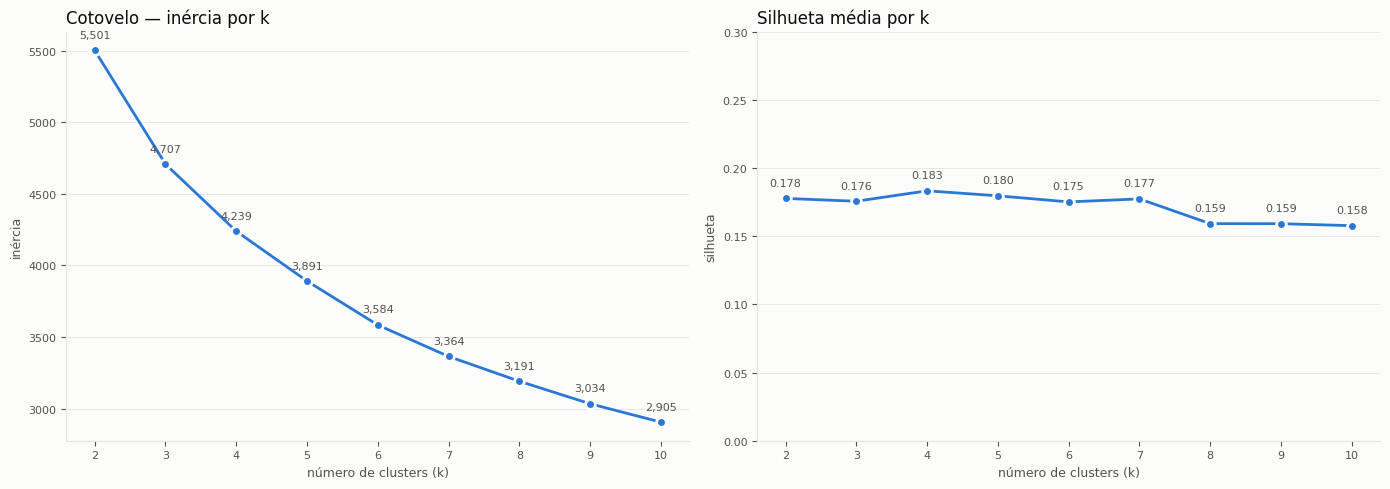

In [5]:
AZUL, TEXTO, TEXTO_2, GRADE, FUNDO = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), facecolor=FUNDO)
for ax, coluna, titulo, fmt in [(ax1, 'inercia', 'Cotovelo — inércia por k', '{:,.0f}'),
                                (ax2, 'silhueta', 'Silhueta média por k', '{:.3f}')]:
    ax.set_facecolor(FUNDO)
    ax.plot(tabela_k.index, tabela_k[coluna], color=AZUL, linewidth=2, marker='o', markersize=7,
            markeredgecolor=FUNDO, markeredgewidth=2)
    for k, v in tabela_k[coluna].items():
        ax.annotate(fmt.format(v), (k, v), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=8, color=TEXTO_2)
    ax.set_title(titulo, loc='left', fontsize=12, color=TEXTO)
    ax.set_xlabel('número de clusters (k)', fontsize=9, color=TEXTO_2)
    ax.set_xticks(tabela_k.index)
    ax.tick_params(colors=TEXTO_2, labelsize=8)
    ax.grid(axis='y', color=GRADE, linewidth=0.6); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
    for lado in ['left', 'bottom']: ax.spines[lado].set_color(GRADE)
ax1.set_ylabel('inércia', fontsize=9, color=TEXTO_2)
ax2.set_ylabel('silhueta', fontsize=9, color=TEXTO_2)
ax2.set_ylim(0, max(0.3, tabela_k['silhueta'].max() * 1.25))
fig.tight_layout()
caminho_fig = RAIZ / 'relatorios' / 'figuras' / '04_cotovelo_silhueta.png'
fig.savefig(caminho_fig, dpi=120, facecolor=fig.get_facecolor())
print('figura salva em', caminho_fig)

In [6]:
tabela_k.to_pickle(ESTADO / 'tabela_k.pkl')

## 2. Segunda opinião: clusterização hierárquica
Ligação de Ward: a cada passo une os dois grupos cuja fusão menos aumenta a variância interna,
o mesmo critério que o K-Means minimiza. Por isso as duas soluções são comparáveis.

In [2]:
import time
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import adjusted_rand_score

inicio = time.perf_counter()
ligacao = linkage(X_modelo.values, method='ward')
print(f'tempo para {len(X_modelo)} lojas: {time.perf_counter() - inicio:.3f} s')

tempo para 1115 lojas: 0.015 s


In [3]:
# alturas das últimas fusões: de (k+1) grupos para k grupos
alturas = ligacao[:, 2]
saltos = pd.DataFrame({'k_apos_fusao': range(1, 16), 'altura_fusao': alturas[::-1][:15]}).set_index('k_apos_fusao')
saltos['salto_ate_proxima'] = saltos['altura_fusao'] - saltos['altura_fusao'].shift(-1)
saltos['salto_relativo_pct'] = (saltos['altura_fusao'] / saltos['altura_fusao'].shift(-1) - 1) * 100
saltos.index.name = 'grupos_restantes'
print(saltos.round(2).to_string())
print('\nleitura: a linha k mostra a altura em que k+1 grupos viram k; salto grande nessa linha = cortar em k+1 grupos é natural')

                  altura_fusao  salto_ate_proxima  salto_relativo_pct
grupos_restantes                                                     
1                        44.68               7.37               19.77
2                        37.31               9.65               34.91
3                        27.65               1.65                6.36
4                        26.00               5.37               26.01
5                        20.63               0.56                2.81
6                        20.07               0.80                4.15
7                        19.27               1.68                9.57
8                        17.59               0.12                0.66
9                        17.47               1.41                8.75
10                       16.07               0.45                2.91
11                       15.61               0.57                3.78
12                       15.04               1.28                9.33
13                  

figura salva em ../relatorios/figuras/04_dendrograma.png


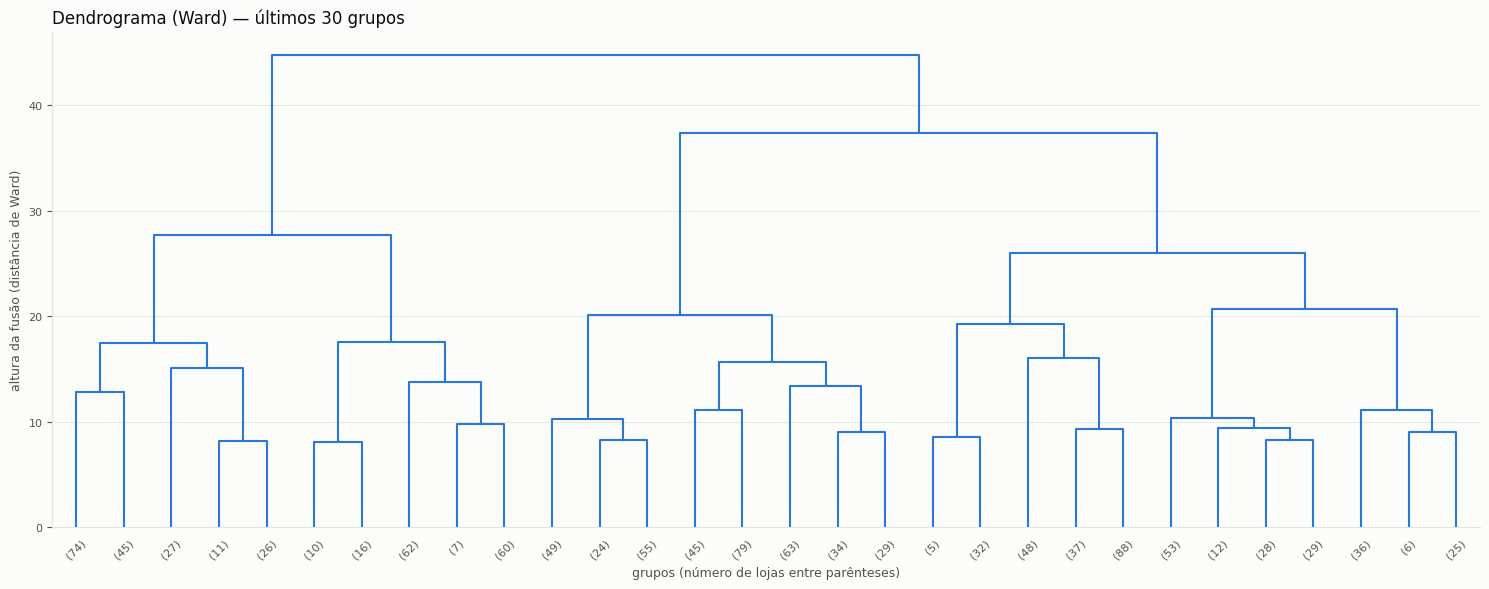

In [4]:
fig, ax = plt.subplots(figsize=(15, 6), facecolor=FUNDO)
ax.set_facecolor(FUNDO)
dendrogram(ligacao, truncate_mode='lastp', p=30, ax=ax, color_threshold=0, above_threshold_color=AZUL,
           show_leaf_counts=True, leaf_font_size=8)
ax.set_title('Dendrograma (Ward) — últimos 30 grupos', loc='left', fontsize=12, color=TEXTO)
ax.set_ylabel('altura da fusão (distância de Ward)', fontsize=9, color=TEXTO_2)
ax.set_xlabel('grupos (número de lojas entre parênteses)', fontsize=9, color=TEXTO_2)
ax.tick_params(colors=TEXTO_2, labelsize=8)
ax.grid(axis='y', color=GRADE, linewidth=0.6); ax.set_axisbelow(True)
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
for lado in ['left', 'bottom']: ax.spines[lado].set_color(GRADE)
fig.tight_layout()
caminho_fig = RAIZ / 'relatorios' / 'figuras' / '04_dendrograma.png'
fig.savefig(caminho_fig, dpi=120, facecolor=fig.get_facecolor())
print('figura salva em', caminho_fig)

In [5]:
# o corte hierárquico em k grupos coincide com o K-Means de mesmo k?
linhas = []
for k in range(2, 9):
    rotulos_hier = fcluster(ligacao, t=k, criterion='maxclust')
    rotulos_kmeans = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X_modelo)
    tamanhos = np.bincount(rotulos_hier)[1:]
    linhas.append({'k': k, 'silhueta_hierarquico': silhouette_score(X_modelo, rotulos_hier),
                   'silhueta_kmeans': tabela_k.loc[k, 'silhueta'],
                   'ari_hier_vs_kmeans': adjusted_rand_score(rotulos_hier, rotulos_kmeans),
                   'menor_grupo_hier': tamanhos.min(), 'maior_grupo_hier': tamanhos.max()})
comparacao_metodos = pd.DataFrame(linhas).set_index('k')
print(comparacao_metodos.round(3).to_string())

   silhueta_hierarquico  silhueta_kmeans  ari_hier_vs_kmeans  menor_grupo_hier  maior_grupo_hier
k                                                                                               
2                 0.171            0.178               0.403               338               777
3                 0.136            0.176               0.560               338               399
4                 0.140            0.183               0.508               155               399
5                 0.124            0.180               0.412               155               378
6                 0.118            0.175               0.411                67               378
7                 0.103            0.177               0.329                67               250
8                 0.107            0.159               0.322                37               250


### Custo do método em bases grandes

In [6]:
gerador = np.random.default_rng(SEED)
medicoes = []
for n in [1115, 2500, 5000, 10000]:
    dados = gerador.normal(size=(n, 6))
    inicio = time.perf_counter()
    linkage(dados, method='ward')
    medicoes.append({'n': n, 'tempo_s': time.perf_counter() - inicio,
                     'pares_de_distancia': n * (n - 1) // 2, 'memoria_distancias_mb': n * (n - 1) / 2 * 8 / 1e6})
medicoes = pd.DataFrame(medicoes).set_index('n')
medicoes['tempo_vs_anterior'] = medicoes['tempo_s'] / medicoes['tempo_s'].shift(1)
print('MEDIDO nesta máquina:')
print(medicoes.round(3).to_string())

print('\nCALCULADO (memória só da matriz de distâncias, 8 bytes por par):')
for n in [10**4, 10**5, 10**6]:
    print(f'  n = {n:>9,}: {n * (n - 1) / 2 * 8 / 1e9:>10,.1f} GB')
for ram in [8, 16, 32]:
    print(f'  com {ram} GB de RAM, o limite teórico é n ~ {int((2 * ram * 1e9 / 8) ** 0.5):,}')

MEDIDO nesta máquina:
       tempo_s  pares_de_distancia  memoria_distancias_mb  tempo_vs_anterior
n                                                                           
1115     0.011              621055                  4.968                NaN
2500     0.106             3123750                 24.990              9.669
5000     0.478            12497500                 99.980              4.506
10000    2.441            49995000                399.960              5.106

CALCULADO (memória só da matriz de distâncias, 8 bytes por par):
  n =    10,000:        0.4 GB
  n =   100,000:       40.0 GB
  n = 1,000,000:    4,000.0 GB
  com 8 GB de RAM, o limite teórico é n ~ 44,721
  com 16 GB de RAM, o limite teórico é n ~ 63,245
  com 32 GB de RAM, o limite teórico é n ~ 89,442


In [7]:
pd.DataFrame(ligacao).to_pickle(ESTADO / 'ligacao_ward.pkl')

## 3. Candidatos de k contra os critérios da Fase 1

In [2]:
from sklearn.metrics import adjusted_rand_score
from scipy.spatial.distance import pdist

K_CANDIDATOS = [2, 3, 5, 8]
modelos_k = {k: KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_modelo) for k in K_CANDIDATOS}
rotulos_k = pd.DataFrame({k: m.labels_ for k, m in modelos_k.items()}, index=X_modelo.index)

# interpretabilidade: centroides em desvios-padrão da rede (|z| alto = traço que dá nome ao grupo)
for k in K_CANDIDATOS:
    centroides = pd.DataFrame(modelos_k[k].cluster_centers_, columns=FEATURES_MODELO)
    centroides.insert(0, 'lojas', np.bincount(modelos_k[k].labels_))
    print(f'k = {k}'); print(centroides.round(2).to_string()); print()

k = 2
   lojas  venda_media_dia_log  ticket_medio  efeito_promo  sazonalidade_log  pico_sabado  distancia_concorrente_log
0    602                 0.02          0.65          0.20              0.21         0.16                       0.62
1    513                -0.02         -0.76         -0.23             -0.24        -0.19                      -0.73

k = 3
   lojas  venda_media_dia_log  ticket_medio  efeito_promo  sazonalidade_log  pico_sabado  distancia_concorrente_log
0    344                 0.44         -0.86         -0.50             -0.31         0.18                      -0.89
1    417                 0.15          0.91          0.04              0.09         0.68                       0.53
2    354                -0.60         -0.24          0.44              0.20        -0.98                       0.24

k = 5
   lojas  venda_media_dia_log  ticket_medio  efeito_promo  sazonalidade_log  pico_sabado  distancia_concorrente_log
0    343                 0.16          1.04         

In [3]:
resumo_interp = []
for k in K_CANDIDATOS:
    c = modelos_k[k].cluster_centers_
    resumo_interp.append({'k': k,
        'clusters_sem_traco_forte': int((np.abs(c).max(axis=1) < 0.75).sum()),
        'tracos_fortes_por_cluster': (np.abs(c) >= 0.75).sum(axis=1).mean(),
        'menor_distancia_entre_centroides': pdist(c).min(),
        'menor_cluster': np.bincount(modelos_k[k].labels_).min()})
print(pd.DataFrame(resumo_interp).set_index('k').round(2).to_string())

   clusters_sem_traco_forte  tracos_fortes_por_cluster  menor_distancia_entre_centroides  menor_cluster
k                                                                                                      
2                         1                       0.50                              2.07            513
3                         0                       1.33                              2.21            344
5                         0                       1.60                              2.23            147
8                         1                       1.75                              1.79             97


### Estabilidade (30 repetições de cada teste)

In [4]:
gerador = np.random.default_rng(SEED)
N_REP = 30
linhas = []
for k in K_CANDIDATOS:
    ref = rotulos_k[k]
    ari_semente, ari_ordem, ari_amostra, troca = [], [], [], []
    for i in range(N_REP):
        ari_semente.append(adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=20, random_state=1000 + i).fit_predict(X_modelo)))
        embaralhado = X_modelo.sample(frac=1, random_state=2000 + i)
        rot = pd.Series(KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(embaralhado), index=embaralhado.index)
        ari_ordem.append(adjusted_rand_score(ref, rot.loc[ref.index]))
        amostra = X_modelo.sample(frac=0.8, random_state=3000 + i)
        rot = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(amostra)
        ari_amostra.append(adjusted_rand_score(ref.loc[amostra.index], rot))
    linhas.append({'k': k, 'ari_semente_medio': np.mean(ari_semente), 'ari_semente_min': np.min(ari_semente),
                   'ari_reordenacao_medio': np.mean(ari_ordem), 'ari_reordenacao_min': np.min(ari_ordem),
                   'ari_subamostra80_medio': np.mean(ari_amostra), 'ari_subamostra80_min': np.min(ari_amostra)})
estabilidade_k = pd.DataFrame(linhas).set_index('k')
print(estabilidade_k.round(3).to_string())

   ari_semente_medio  ari_semente_min  ari_reordenacao_medio  ari_reordenacao_min  ari_subamostra80_medio  ari_subamostra80_min
k                                                                                                                              
2              0.982            0.926                  0.975                0.926                   0.879                 0.741
3              0.992            0.984                  0.993                0.984                   0.937                 0.875
5              0.900            0.742                  0.907                0.706                   0.754                 0.502
8              0.852            0.577                  0.844                0.616                   0.734                 0.471


### Melhor que o baseline (variância explicada, eta²)

In [5]:
def eta2(valores, grupos):
    media_geral = valores.mean()
    entre = valores.groupby(grupos).agg(lambda s: len(s) * (s.mean() - media_geral) ** 2).sum()
    return entre / ((valores - media_geral) ** 2).sum()

metricas_modelo = ['venda_media_dia_log', 'ticket_medio', 'efeito_promo', 'sazonalidade_log', 'pico_sabado', 'distancia_concorrente_log']
metricas_fora = ['clientes_medios_dia_log', 'volatilidade', 'prop_domingos_abertos']
segmentacoes = {'tipo_loja (4)': base_transformada['tipo_loja'], 'sortimento (3)': base_transformada['sortimento']}
segmentacoes.update({f'cluster k={k}': rotulos_k[k] for k in K_CANDIDATOS})
tabela_eta = pd.DataFrame({nome: {m: eta2(base_transformada[m], g) for m in metricas_modelo + metricas_fora}
                           for nome, g in segmentacoes.items()})
tabela_eta.loc['MÉDIA no modelo'] = tabela_eta.loc[metricas_modelo].mean()
tabela_eta.loc['MÉDIA fora do modelo'] = tabela_eta.loc[metricas_fora].mean()
print((tabela_eta * 100).round(1).to_string())

                           tipo_loja (4)  sortimento (3)  cluster k=2  cluster k=3  cluster k=5  cluster k=8
venda_media_dia_log                  1.8             2.8          0.0         18.0         14.6         41.9
ticket_medio                        42.3            11.1         49.1         55.8         54.1         60.8
efeito_promo                         6.0             6.9          4.6         13.8         39.2         50.7
sazonalidade_log                     3.5             5.9          5.0          4.6         46.1         51.3
pico_sabado                         22.4             5.4          3.0         49.0         47.6         51.8
distancia_concorrente_log            8.3             3.1         44.9         36.7         49.5         57.4
clientes_medios_dia_log             19.2             5.9         14.3         33.4         27.8         49.2
volatilidade                         2.0             1.5          1.4         35.5         38.8         44.6
prop_domingos_abert

In [6]:
# o tipo b (17 lojas de alto fluxo) fica junto?
tipo_b = base_transformada['tipo_loja'] == 'b'
for k in K_CANDIDATOS:
    dist_b = rotulos_k.loc[tipo_b, k].value_counts()
    print(f'k = {k}: tipo b em {len(dist_b)} cluster(s), maior concentração {dist_b.iloc[0]} de 17 '
          f'(cluster de {int((rotulos_k[k] == dist_b.index[0]).sum())} lojas)')

k = 2: tipo b em 1 cluster(s), maior concentração 17 de 17 (cluster de 513 lojas)
k = 3: tipo b em 2 cluster(s), maior concentração 16 de 17 (cluster de 344 lojas)
k = 5: tipo b em 3 cluster(s), maior concentração 12 de 17 (cluster de 188 lojas)
k = 8: tipo b em 3 cluster(s), maior concentração 11 de 17 (cluster de 105 lojas)


### Quantificado (prévia): gap até a mediana dos pares

In [7]:
venda = base_transformada['venda_media_dia']
dias_abertos_ano = perfil_lojas['pct_dias_abertos'] * 365
agrupamentos = {'rede inteira (k=1)': pd.Series(0, index=venda.index), 'tipo_loja': base_transformada['tipo_loja']}
agrupamentos.update({f'cluster k={k}': rotulos_k[k] for k in K_CANDIDATOS})
linhas = []
for nome, g in agrupamentos.items():
    mediana_pares = venda.groupby(g).transform('median')
    gap_dia = (mediana_pares - venda).clip(lower=0)
    gap_anual = (gap_dia * dias_abertos_ano).sum()
    cv_interno = (venda.groupby(g).std() / venda.groupby(g).mean()).mean()
    linhas.append({'agrupamento': nome, 'lojas_abaixo_da_mediana': int((gap_dia > 0).sum()),
                   'gap_anual_R$_mi': gap_anual / 1e6, 'captura_25pct_R$_mi': gap_anual * 0.25 / 1e6,
                   'gap_mediano_pct': (gap_dia[gap_dia > 0] / mediana_pares[gap_dia > 0]).median() * 100,
                   'cv_venda_dentro_do_grupo': cv_interno})
print(pd.DataFrame(linhas).set_index('agrupamento').round(2).to_string())
print(f'\nfaturamento anual estimado da rede: R$ {(venda * dias_abertos_ano).sum() / 1e6:,.0f} mi')

                    lojas_abaixo_da_mediana  gap_anual_R$_mi  captura_25pct_R$_mi  gap_mediano_pct  cv_venda_dentro_do_grupo
agrupamento                                                                                                                 
rede inteira (k=1)                      557           228.10                57.03            19.25                      0.34
tipo_loja                               557           232.40                58.10            19.65                      0.35
cluster k=2                             557           226.80                56.70            19.07                      0.34
cluster k=3                             557           197.99                49.50            16.12                      0.30
cluster k=5                             556           212.53                53.13            16.89                      0.31
cluster k=8                             556           176.31                44.08            13.58                      0.26


In [8]:
rotulos_k.to_pickle(ESTADO / 'rotulos_k.pkl')
estabilidade_k.to_pickle(ESTADO / 'estabilidade_k.pkl')

## 4. A troca de pico_sabado por volatilidade (conjunto da apostila) muda a estabilidade em k = 5?

In [2]:
from sklearn.preprocessing import StandardScaler

def testar_estabilidade(X, k, n_rep=30):
    ref = pd.Series(KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X), index=X.index)
    semente, ordem, amostra = [], [], []
    for i in range(n_rep):
        semente.append(adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=20, random_state=1000 + i).fit_predict(X)))
        emb = X.sample(frac=1, random_state=2000 + i)
        rot = pd.Series(KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(emb), index=emb.index)
        ordem.append(adjusted_rand_score(ref, rot.loc[ref.index]))
        sub = X.sample(frac=0.8, random_state=3000 + i)
        amostra.append(adjusted_rand_score(ref.loc[sub.index], KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(sub)))
    return {'silhueta': silhouette_score(X, ref), 'ari_semente': np.mean(semente), 'ari_reordenacao': np.mean(ordem),
            'ari_subamostra80': np.mean(amostra), 'ari_subamostra80_min': np.min(amostra), 'menor_cluster': ref.value_counts().min()}

def escalonar(colunas):
    return pd.DataFrame(StandardScaler().fit_transform(base_transformada[colunas]), columns=colunas, index=base_transformada.index)

conjuntos = {
    'nosso (com pico_sabado)': FEATURES_MODELO,
    'apostila (com volatilidade)': ['venda_media_dia_log', 'ticket_medio', 'efeito_promo', 'sazonalidade_log', 'volatilidade', 'distancia_concorrente_log'],
    'os dois (7 features)': FEATURES_MODELO + ['volatilidade'],
    'nenhum dos dois (5 features)': [c for c in FEATURES_MODELO if c != 'pico_sabado'],
}
comparacao_conjuntos = pd.DataFrame({nome: testar_estabilidade(escalonar(cols), 5) for nome, cols in conjuntos.items()}).T
print('k = 5, 30 repetições por teste')
print(comparacao_conjuntos.round(3).to_string())

k = 5, 30 repetições por teste
                              silhueta  ari_semente  ari_reordenacao  ari_subamostra80  ari_subamostra80_min  menor_cluster
nosso (com pico_sabado)          0.180        0.900            0.907             0.754                 0.502          147.0
apostila (com volatilidade)      0.181        0.977            0.977             0.755                 0.522          154.0
os dois (7 features)             0.165        0.803            0.814             0.639                 0.456          156.0
nenhum dos dois (5 features)     0.186        0.954            0.959             0.826                 0.484          153.0


In [3]:
# qual feature do nosso conjunto mais pesa na instabilidade? (retirando uma de cada vez)
retirada = pd.DataFrame({f'sem {c}': testar_estabilidade(escalonar([f for f in FEATURES_MODELO if f != c]), 5)
                         for c in FEATURES_MODELO}).T
print(retirada[['silhueta', 'ari_semente', 'ari_subamostra80', 'ari_subamostra80_min']].round(3).to_string())

                               silhueta  ari_semente  ari_subamostra80  ari_subamostra80_min
sem venda_media_dia_log           0.217        0.969             0.891                 0.599
sem ticket_medio                  0.172        0.980             0.797                 0.470
sem efeito_promo                  0.206        0.982             0.942                 0.839
sem sazonalidade_log              0.197        0.967             0.852                 0.632
sem pico_sabado                   0.186        0.954             0.826                 0.484
sem distancia_concorrente_log     0.188        0.965             0.839                 0.655


In [4]:
# os dois conjuntos nos outros k
linhas = []
for k in [3, 4, 5, 6]:
    for nome in ['nosso (com pico_sabado)', 'apostila (com volatilidade)']:
        r = testar_estabilidade(escalonar(conjuntos[nome]), k)
        linhas.append({'k': k, 'conjunto': nome, **{c: r[c] for c in ['silhueta', 'ari_semente', 'ari_reordenacao', 'ari_subamostra80', 'ari_subamostra80_min']}})
print(pd.DataFrame(linhas).set_index(['k', 'conjunto']).round(3).to_string())

                               silhueta  ari_semente  ari_reordenacao  ari_subamostra80  ari_subamostra80_min
k conjunto                                                                                                   
3 nosso (com pico_sabado)         0.176        0.992            0.993             0.937                 0.875
  apostila (com volatilidade)     0.176        0.971            0.981             0.853                 0.738
4 nosso (com pico_sabado)         0.183        0.981            0.978             0.906                 0.617
  apostila (com volatilidade)     0.178        0.923            0.938             0.817                 0.479
5 nosso (com pico_sabado)         0.180        0.900            0.907             0.754                 0.502
  apostila (com volatilidade)     0.181        0.977            0.977             0.755                 0.522
6 nosso (com pico_sabado)         0.175        0.939            0.938             0.821                 0.574
  apostila

## 5. Modelo com k = 5

In [2]:
import joblib
from sklearn.metrics import silhouette_samples
from scipy.stats import chi2_contingency

modelo_k5 = KMeans(n_clusters=5, n_init=20, random_state=SEED).fit(X_modelo)
base_transformada['cluster'] = modelo_k5.labels_
print('rótulos idênticos aos da comparação de k anterior:', bool((base_transformada['cluster'] == rotulos_k[5]).all()))
print(f'inércia: {modelo_k5.inertia_:.1f} | silhueta: {silhouette_score(X_modelo, modelo_k5.labels_):.3f}')

tamanhos = base_transformada['cluster'].value_counts().sort_index().rename('lojas').to_frame()
tamanhos['pct'] = (tamanhos['lojas'] / len(base_transformada) * 100).round(1)
print(tamanhos.to_string())
print(f"\nmaior / menor: {tamanhos['lojas'].max() / tamanhos['lojas'].min():.2f}x | tamanho se fossem iguais: {len(base_transformada) / 5:.0f} lojas (20%)")

rótulos idênticos aos da comparação de k anterior: True
inércia: 3890.5 | silhueta: 0.180
         lojas   pct
cluster             
0          343  30.8
1          147  13.2
2          258  23.1
3          179  16.1
4          188  16.9

maior / menor: 2.33x | tamanho se fossem iguais: 223 lojas (20%)


In [3]:
# o maior cluster é um grupo com identidade ou um "resto"?
centroides = pd.DataFrame(modelo_k5.cluster_centers_, columns=FEATURES_MODELO).round(2)
distancias = np.linalg.norm(X_modelo.values - modelo_k5.cluster_centers_[modelo_k5.labels_], axis=1)
coesao = pd.DataFrame({
    'lojas': tamanhos['lojas'],
    'distancia_media_ao_centroide': pd.Series(distancias).groupby(modelo_k5.labels_).mean(),
    'silhueta_media': pd.Series(silhouette_samples(X_modelo, modelo_k5.labels_)).groupby(modelo_k5.labels_).mean(),
    'pct_silhueta_negativa': pd.Series(silhouette_samples(X_modelo, modelo_k5.labels_) < 0).groupby(modelo_k5.labels_).mean() * 100,
    'distancia_do_centroide_a_media_da_rede': np.linalg.norm(modelo_k5.cluster_centers_, axis=1),
})
print(coesao.round(3).to_string())
print('\ncentroides (desvios-padrão da rede):'); print(centroides.to_string())

   lojas  distancia_media_ao_centroide  silhueta_media  pct_silhueta_negativa  distancia_do_centroide_a_media_da_rede
0    343                         1.638           0.229                  0.875                                   1.398
1    147                         2.042           0.092                 22.449                                   1.827
2    258                         1.608           0.224                  0.000                                   1.385
3    179                         1.879           0.129                 12.291                                   1.732
4    188                         1.887           0.146                 11.170                                   1.799

centroides (desvios-padrão da rede):
   venda_media_dia_log  ticket_medio  efeito_promo  sazonalidade_log  pico_sabado  distancia_concorrente_log
0                 0.16          1.04          0.06             -0.02         0.70                       0.59
1                 0.19         -0.90

### Como as binárias que ficaram fora do modelo se distribuem

In [4]:
base_transformada['abre_domingo'] = (base_transformada['prop_domingos_abertos'] > 0).astype(int)
binarias = base_transformada.groupby('cluster').agg(
    lojas=('cluster', 'size'),
    promo_continua_n=('promo_continua', 'sum'),
    promo_continua_pct=('promo_continua', lambda s: s.mean() * 100),
    abre_domingo_n=('abre_domingo', 'sum'),
    abre_domingo_pct=('abre_domingo', lambda s: s.mean() * 100),
    distancia_imputada_n=('distancia_imputada', 'sum'),
)
print(binarias.round(1).to_string())
print(f"\nrede: promo_continua {base_transformada['promo_continua'].mean():.1%} | abre_domingo {base_transformada['abre_domingo'].mean():.1%} ({base_transformada['abre_domingo'].sum()} lojas)")
for coluna in ['promo_continua', 'abre_domingo']:
    tabela = pd.crosstab(base_transformada['cluster'], base_transformada[coluna])
    qui2, p_valor, _, esperado = chi2_contingency(tabela)
    v_cramer = np.sqrt(qui2 / (tabela.values.sum() * (min(tabela.shape) - 1)))
    print(f'{coluna}: qui² = {qui2:.1f} | p = {p_valor:.2e} | V de Cramér = {v_cramer:.3f} | menor frequência esperada = {esperado.min():.1f}')

         lojas  promo_continua_n  promo_continua_pct  abre_domingo_n  abre_domingo_pct  distancia_imputada_n
cluster                                                                                                     
0          343               214                62.4               3               0.9                     0
1          147                68                46.3              13               8.8                     0
2          258               111                43.0               4               1.6                     3
3          179               122                68.2               0               0.0                     0
4          188                56                29.8              13               6.9                     0

rede: promo_continua 51.2% | abre_domingo 3.0% (33 lojas)
promo_continua: qui² = 80.6 | p = 1.28e-16 | V de Cramér = 0.269 | menor frequência esperada = 71.7
abre_domingo: qui² = 40.4 | p = 3.59e-08 | V de Cramér = 0.190 | menor frequên

In [5]:
joblib.dump(modelo_k5, RAIZ / 'modelos' / 'kmeans_k5.joblib')
base_transformada.to_pickle(ESTADO / 'base_transformada.pkl')
base_transformada.to_parquet(PROCESSADOS / 'base_lojas_clusters.parquet')

## 6. Revisão: modelagem com o conjunto final de features
As features foram revisadas na seção 14 do notebook 03. Esta seção refaz a modelagem sobre a nova matriz.
**As seções 1 a 5 ficam como registro do conjunto anterior.**

In [2]:
X_modelo = pd.read_parquet(PROCESSADOS / 'X_modelo.parquet')
base = pd.read_parquet(PROCESSADOS / 'base_lojas.parquet')
FEATURES_MODELO = X_modelo.columns.tolist()
print(FEATURES_MODELO)

resultados = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_modelo)
    tamanhos = np.bincount(modelo.labels_)
    resultados.append({'k': k, 'inercia': modelo.inertia_, 'silhueta': silhouette_score(X_modelo, modelo.labels_),
                       'menor_cluster': tamanhos.min(), 'maior_cluster': tamanhos.max()})
tabela_k = pd.DataFrame(resultados).set_index('k')
tabela_k['queda_inercia_pct'] = -tabela_k['inercia'].pct_change() * 100
print(tabela_k.assign(silhueta=tabela_k['silhueta'].map('{:.3f}'.format)).round(1).to_string())

['venda_media_dia', 'ticket_medio', 'efeito_promo', 'volatilidade', 'sazonalidade', 'distancia_concorrente']


    inercia silhueta  menor_cluster  maior_cluster  queda_inercia_pct
k                                                                    
2    5338.8    0.187            512            603                NaN
3    4439.0    0.198            316            458               16.9
4    3989.6    0.199            133            442               10.1
5    3632.6    0.202             65            414                8.9
6    3366.5    0.187             62            388                7.3
7    3121.7    0.170             64            253                7.3
8    2959.4    0.170             39            231                5.2
9    2817.1    0.172             31            223                4.8
10   2680.9    0.163             22            193                4.8


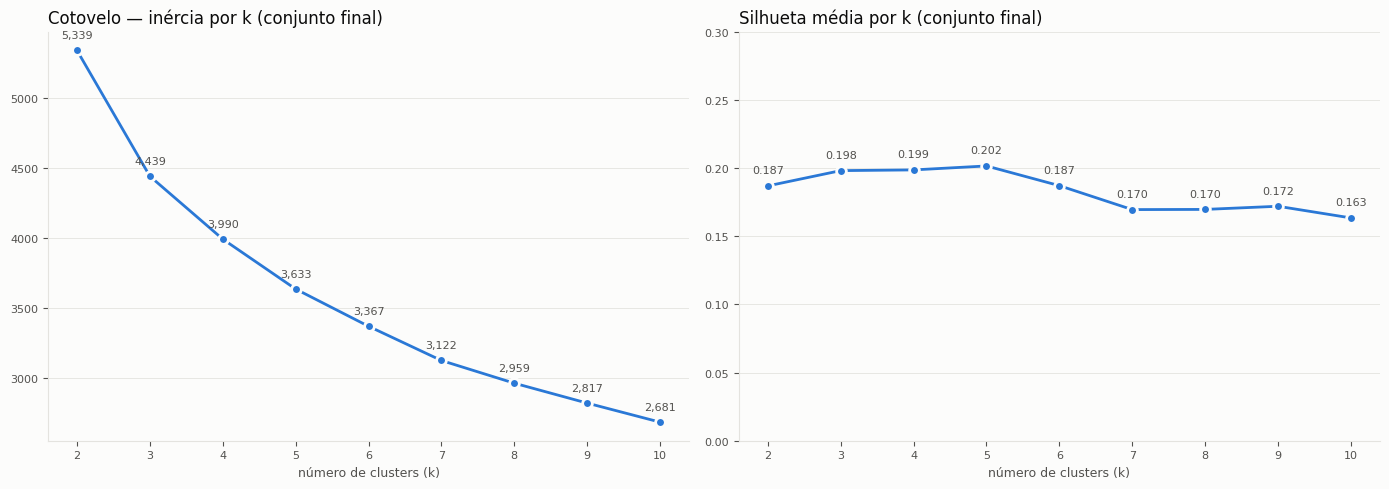

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), facecolor=FUNDO)
for ax, coluna, titulo, fmt in [(ax1, 'inercia', 'Cotovelo — inércia por k (conjunto final)', '{:,.0f}'),
                                (ax2, 'silhueta', 'Silhueta média por k (conjunto final)', '{:.3f}')]:
    ax.set_facecolor(FUNDO)
    ax.plot(tabela_k.index, tabela_k[coluna], color=AZUL, linewidth=2, marker='o', markersize=7, markeredgecolor=FUNDO, markeredgewidth=2)
    for k, v in tabela_k[coluna].items():
        ax.annotate(fmt.format(v), (k, v), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=8, color=TEXTO_2)
    ax.set_title(titulo, loc='left', fontsize=12, color=TEXTO)
    ax.set_xlabel('número de clusters (k)', fontsize=9, color=TEXTO_2)
    ax.set_xticks(tabela_k.index); ax.tick_params(colors=TEXTO_2, labelsize=8)
    ax.grid(axis='y', color=GRADE, linewidth=0.6); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
    for lado in ['left', 'bottom']: ax.spines[lado].set_color(GRADE)
ax2.set_ylim(0, 0.3)
fig.tight_layout()
fig.savefig(RAIZ / 'relatorios' / 'figuras' / '04_cotovelo_silhueta.png', dpi=120, facecolor=fig.get_facecolor())

                 altura_inferior  altura_superior  folga_de_altura
grupos_no_corte                                                   
2                          39.90            42.82             2.93
3                          30.94            39.90             8.95
4                          26.99            30.94             3.95
5                          26.33            26.99             0.66
6                          22.93            26.33             3.40
7                          17.78            22.93             5.15
8                          16.96            17.78             0.82
9                          16.23            16.96             0.73
10                         15.91            16.23             0.32


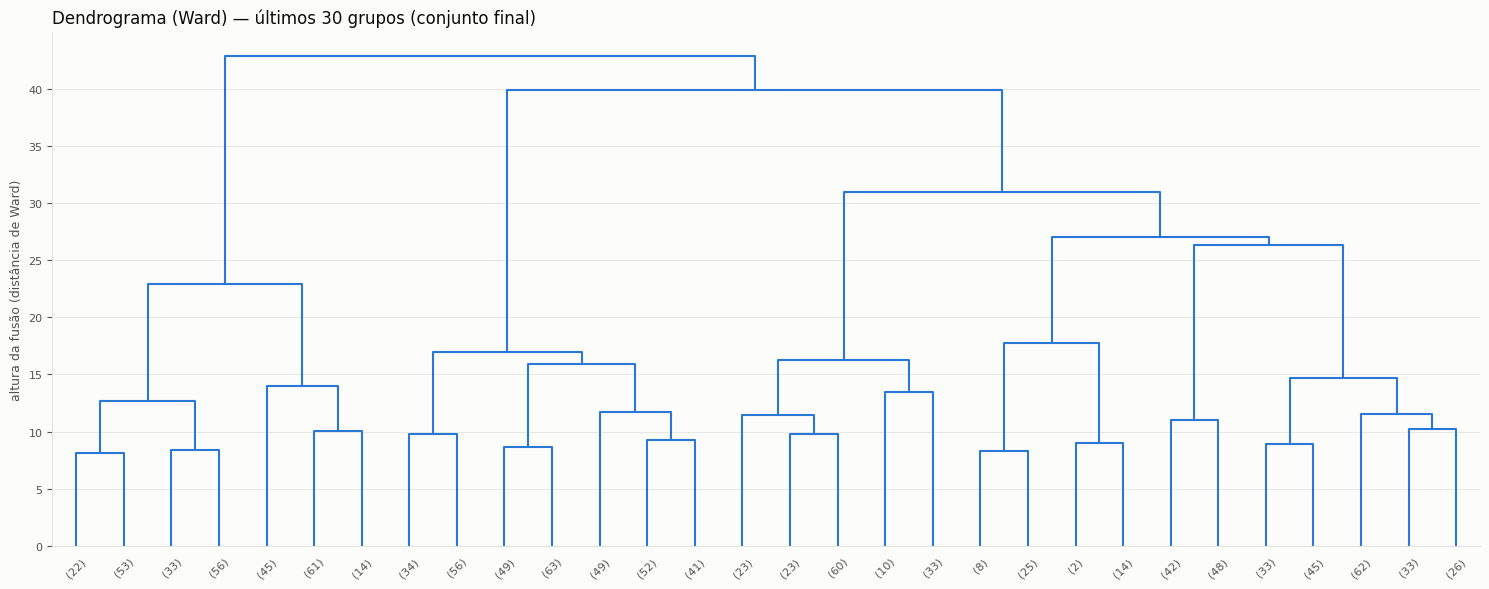

In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

ligacao = linkage(X_modelo.values, method='ward')
alturas = ligacao[:, 2][::-1][:10]
saltos = pd.DataFrame({'grupos_no_corte': range(2, 11), 'folga_de_altura': alturas[:9] - alturas[1:10]}).set_index('grupos_no_corte')
saltos['altura_inferior'] = alturas[1:10]
saltos['altura_superior'] = alturas[:9]
print(saltos[['altura_inferior', 'altura_superior', 'folga_de_altura']].round(2).to_string())

fig, ax = plt.subplots(figsize=(15, 6), facecolor=FUNDO)
ax.set_facecolor(FUNDO)
dendrogram(ligacao, truncate_mode='lastp', p=30, ax=ax, color_threshold=0, above_threshold_color=AZUL, show_leaf_counts=True, leaf_font_size=8)
ax.set_title('Dendrograma (Ward) — últimos 30 grupos (conjunto final)', loc='left', fontsize=12, color=TEXTO)
ax.set_ylabel('altura da fusão (distância de Ward)', fontsize=9, color=TEXTO_2)
ax.tick_params(colors=TEXTO_2, labelsize=8); ax.grid(axis='y', color=GRADE, linewidth=0.6); ax.set_axisbelow(True)
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
for lado in ['left', 'bottom']: ax.spines[lado].set_color(GRADE)
fig.tight_layout()
fig.savefig(RAIZ / 'relatorios' / 'figuras' / '04_dendrograma.png', dpi=120, facecolor=fig.get_facecolor())

### Candidatos de k contra os critérios

In [5]:
def eta2(valores, grupos):
    media_geral = valores.mean()
    return valores.groupby(grupos).agg(lambda s: len(s) * (s.mean() - media_geral) ** 2).sum() / ((valores - media_geral) ** 2).sum() * 100

def estabilidade(X, k, n_rep=30):
    ref = pd.Series(KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X), index=X.index)
    semente, ordem, amostra = [], [], []
    for i in range(n_rep):
        semente.append(adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=20, random_state=1000 + i).fit_predict(X)))
        emb = X.sample(frac=1, random_state=2000 + i)
        ordem.append(adjusted_rand_score(ref.loc[emb.index], KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(emb)))
        sub = X.sample(frac=0.8, random_state=3000 + i)
        amostra.append(adjusted_rand_score(ref.loc[sub.index], KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(sub)))
    return ref, np.mean(semente), np.mean(ordem), np.mean(amostra), np.min(amostra)

metricas_negocio = ['venda_media_dia', 'ticket_medio', 'clientes_medios_dia', 'efeito_promo', 'volatilidade', 'sazonalidade',
                    'pico_sabado', 'distancia_concorrente']
venda = base['venda_media_dia']
dias_abertos_ano = perfil_lojas['pct_dias_abertos'] * 365
linhas, rotulos_k = [], {}
for k in [2, 3, 4, 5, 6, 8]:
    ref, s, o, a, a_min = estabilidade(X_modelo, k)
    rotulos_k[k] = ref
    gap = (venda.groupby(ref).transform('median') - venda).clip(lower=0)
    linhas.append({'k': k, 'silhueta': silhouette_score(X_modelo, ref), 'ari_semente': s, 'ari_reordenacao': o, 'ari_subamostra80': a,
                   'ari_subamostra80_min': a_min, 'eta2_medio_pct': np.mean([eta2(base[m], ref) for m in metricas_negocio]),
                   'eta2_venda_pct': eta2(venda, ref), 'gap_anual_R$_mi': (gap * dias_abertos_ano).sum() / 1e6,
                   'menor_cluster': ref.value_counts().min(), 'maior_cluster': ref.value_counts().max()})
candidatos_k = pd.DataFrame(linhas).set_index('k')
print(candidatos_k.round(3).to_string())
print('\nreferência tipo_loja: eta² médio', round(np.mean([eta2(base[m], base['tipo_loja']) for m in metricas_negocio]), 1),
      '| eta² venda', round(eta2(venda, base['tipo_loja']), 1))

   silhueta  ari_semente  ari_reordenacao  ari_subamostra80  ari_subamostra80_min  eta2_medio_pct  eta2_venda_pct  gap_anual_R$_mi  menor_cluster  maior_cluster
k                                                                                                                                                               
2     0.187        1.000            1.000             0.859                 0.577          20.290          10.309          211.458            512            603
3     0.198        0.992            0.990             0.925                 0.727          30.005          13.615          201.543            316            458
4     0.199        0.984            0.984             0.911                 0.650          37.302          15.858          207.639            133            442
5     0.202        0.992            0.990             0.888                 0.690          42.703          28.331          205.512             65            414
6     0.187        0.949          

### Modelo final: k = 5

In [6]:
modelo_k5 = KMeans(n_clusters=5, n_init=20, random_state=SEED).fit(X_modelo)
base['cluster'] = modelo_k5.labels_
base['abre_domingo'] = (base['prop_domingos_abertos'] > 0).astype(int)

tamanhos = base['cluster'].value_counts().sort_index().rename('lojas').to_frame()
tamanhos['pct'] = (tamanhos['lojas'] / len(base) * 100).round(1)
print(f'inércia: {modelo_k5.inertia_:.1f} | silhueta: {silhouette_score(X_modelo, modelo_k5.labels_):.3f}')
print(tamanhos.to_string())

exaustivo = KMeans(n_clusters=5, n_init=500, random_state=SEED).fit(X_modelo)
print(f'\ninércia com n_init=500: {exaustivo.inertia_:.1f} | ARI contra o modelo final: {adjusted_rand_score(modelo_k5.labels_, exaustivo.labels_):.3f}')

inércia: 3632.6 | silhueta: 0.202
         lojas   pct
cluster             
0          292  26.2
1          414  37.1
2           65   5.8
3          165  14.8
4          179  16.1



inércia com n_init=500: 3632.5 | ARI contra o modelo final: 0.997


In [7]:
centroides = pd.DataFrame(modelo_k5.cluster_centers_, columns=FEATURES_MODELO).round(2)
centroides.insert(0, 'lojas', tamanhos['lojas'])
print('centroides (desvios-padrão da rede):'); print(centroides.to_string())

binarias = base.groupby('cluster').agg(lojas=('cluster', 'size'), promo_continua_pct=('promo_continua', lambda s: s.mean() * 100),
                                       abre_domingo_n=('abre_domingo', 'sum'), abre_domingo_pct=('abre_domingo', lambda s: s.mean() * 100))
print('\nbinárias fora do modelo:'); print(binarias.round(1).to_string())
print('\ntipo_loja por cluster:'); print(pd.crosstab(base['cluster'], base['tipo_loja'], margins=True, margins_name='total').to_string())
print('\nsortimento por cluster:'); print(pd.crosstab(base['cluster'], base['sortimento'], margins=True, margins_name='total').to_string())

centroides (desvios-padrão da rede):
   lojas  venda_media_dia  ticket_medio  efeito_promo  volatilidade  sazonalidade  distancia_concorrente
0    292            -0.56         -0.59          0.26          0.08         -0.28                  -0.70
1    414             0.14          0.84         -0.34         -0.35          0.04                   0.62
2     65            -0.26         -0.72         -0.54          0.70          2.44                   0.21
3    165            -0.37          0.12          1.54          1.56          0.09                   0.40
4    179             1.02         -0.84         -0.87         -1.02         -0.60                  -0.73

binárias fora do modelo:
         lojas  promo_continua_pct  abre_domingo_n  abre_domingo_pct
cluster                                                             
0          292                50.0               3               1.0
1          414                57.5               1               0.2
2           65                5

In [8]:
joblib.dump(modelo_k5, RAIZ / 'modelos' / 'kmeans_k5.joblib')
base.to_parquet(PROCESSADOS / 'base_lojas_clusters.parquet')
base.to_pickle(ESTADO / 'base_clusters.pkl')
candidatos_k.to_pickle(ESTADO / 'candidatos_k.pkl')

### Complementos da revisão: cotovelo, referência embaralhada, hierárquico e coesão por cluster

In [2]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.stats import chi2_contingency

inercias, silhuetas, rot_km = {}, {}, {}
for k in range(2, 11):
    m = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_modelo)
    inercias[k], silhuetas[k], rot_km[k] = m.inertia_, silhouette_score(X_modelo, m.labels_), m.labels_
ks = np.array(list(inercias)); v = np.array(list(inercias.values()))
dist_reta = (1 - (ks - 2) / 8) - (v - v.min()) / (v.max() - v.min())
print('distância à reta k=2..10:', dict(zip(ks.tolist(), dist_reta.round(3).tolist())), '| cotovelo geométrico: k =', int(ks[dist_reta.argmax()]))

gerador = np.random.default_rng(SEED)
ref = {}
for k in range(2, 11):
    s = []
    for _ in range(5):
        Xe = X_modelo.apply(lambda col: gerador.permutation(col.values))
        s.append(silhouette_score(Xe, KMeans(n_clusters=k, n_init=5, random_state=SEED).fit_predict(Xe)))
    ref[k] = np.mean(s)
print('silhueta real x embaralhada:', {k: (round(silhuetas[k], 3), round(ref[k], 3)) for k in ref})

ligacao = linkage(X_modelo.values, method='ward')
linhas = []
for k in [3, 4, 5, 6]:
    rh = fcluster(ligacao, t=k, criterion='maxclust')
    linhas.append({'k': k, 'silhueta_hierarquico': silhouette_score(X_modelo, rh), 'silhueta_kmeans': silhuetas[k],
                   'ari_hier_vs_kmeans': adjusted_rand_score(rh, rot_km[k])})
print(pd.DataFrame(linhas).set_index('k').round(3).to_string())

distância à reta k=2..10: {2: 0.0, 3: 0.214, 4: 0.258, 5: 0.267, 6: 0.242, 7: 0.209, 8: 0.145, 9: 0.074, 10: 0.0} | cotovelo geométrico: k = 5


silhueta real x embaralhada: {2: (0.187, np.float64(0.119)), 3: (0.198, np.float64(0.117)), 4: (0.199, np.float64(0.12)), 5: (0.202, np.float64(0.124)), 6: (0.187, np.float64(0.128)), 7: (0.17, np.float64(0.129)), 8: (0.17, np.float64(0.125)), 9: (0.172, np.float64(0.12)), 10: (0.163, np.float64(0.124))}
   silhueta_hierarquico  silhueta_kmeans  ari_hier_vs_kmeans
k                                                           
3                 0.123            0.198               0.332
4                 0.127            0.199               0.307
5                 0.135            0.202               0.387
6                 0.134            0.187               0.454


In [3]:
sil = pd.Series(silhouette_samples(X_modelo, base['cluster']), index=base.index)
coesao = pd.DataFrame({'lojas': base['cluster'].value_counts().sort_index(),
                       'silhueta_media': sil.groupby(base['cluster']).mean(),
                       'pct_silhueta_negativa': (sil < 0).groupby(base['cluster']).mean() * 100})
print(coesao.round(3).to_string())
for coluna in ['promo_continua', 'abre_domingo']:
    tabela = pd.crosstab(base['cluster'], base[coluna])
    qui2, p_valor, _, _ = chi2_contingency(tabela)
    print(f'{coluna}: V de Cramér = {np.sqrt(qui2 / tabela.values.sum()):.3f} | p = {p_valor:.1e}')
venda = base['venda_media_dia']
print('CV da venda dentro do grupo - cluster:', round((venda.groupby(base['cluster']).std() / venda.groupby(base['cluster']).mean()).mean(), 3),
      '| tipo_loja:', round((venda.groupby(base['tipo_loja']).std() / venda.groupby(base['tipo_loja']).mean()).mean(), 3),
      '| rede:', round(venda.std() / venda.mean(), 3))

         lojas  silhueta_media  pct_silhueta_negativa
cluster                                              
0          292           0.165                  5.137
1          414           0.278                  0.000
2           65           0.079                 33.846
3          165           0.198                  7.879
4          179           0.131                 18.436
promo_continua: V de Cramér = 0.166 | p = 3.6e-06
abre_domingo: V de Cramér = 0.288 | p = 4.0e-19
CV da venda dentro do grupo - cluster: 0.284 | tipo_loja: 0.351 | rede: 0.344
